In [3]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import os


In [4]:
# Global style (feel free to tweak)
mpl.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 200,
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.labelsize": 13,
    "axes.facecolor": "#EEF3FA",   # light blue/grey background
    "figure.facecolor": "white",
    "axes.edgecolor": "#D0D7E2",
    "axes.grid": True,
    "grid.color": "white",
    "grid.linewidth": 1.2,
    "grid.alpha": 1.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
    "legend.facecolor": "white",
})


In [5]:
sector_etfs = {
    "Basic Materials": "XLB",
    "Communication Services": "XLC",
    "Consumer Cyclical": "XLY",
    "Consumer Defensive": "XLP",
    "Energy": "XLE",
    "Financial Services": "XLF",
    "Healthcare": "XLV",
    "Industrials": "XLI",
    "Real Estate": "XLRE",
    "Technology": "XLK",
    "Utilities": "XLU",
}


In [6]:
DATA_DIR = Path("data_processed")

meta     = pd.read_parquet(DATA_DIR / "meta_clean.parquet")
ret_tidy = pd.read_parquet(DATA_DIR / "returns_tidy.parquet", columns=["Date","Symbol","log_return"])
stocks   = pd.read_parquet(DATA_DIR / "stocks_clean.parquet", columns=["Date","Symbol","Volume"])
etf_ret  = pd.read_parquet(DATA_DIR / "etf_returns.parquet")  # wide columns tickers

ret_tidy["Date"] = pd.to_datetime(ret_tidy["Date"])
stocks["Date"]   = pd.to_datetime(stocks["Date"])
etf_ret.index    = pd.to_datetime(etf_ret.index)

def is_etf_flag(x) -> bool:
    if pd.isna(x): return False
    if isinstance(x, str):
        return x.strip().upper() in {"Y","YES","TRUE","T","1","ETF"}
    return bool(x)


In [7]:
def analyze_sector(
    sector_name,
    etf_ticker,
    cap=0.10,
    lag=1,
    windows=(60, 120),
    bad_ret_thresh=1.0,
    min_good_frac=0.98,
):
    # 1) universe = stocks in sector (exclude ETFs)
    tickers = meta.loc[
        meta["sector"].astype(str).str.lower().eq(sector_name.lower())
        & (~meta["etf"].map(is_etf_flag)),
        "ticker",
    ].dropna().unique()

    if len(tickers) == 0:
        return None, f"No stock tickers found in meta for sector='{sector_name}'."

    # 2) pull returns + volume for those tickers (long -> wide)
    r = ret_tidy[ret_tidy["Symbol"].isin(tickers)].dropna()
    v = stocks[stocks["Symbol"].isin(tickers)].dropna()

    if r.empty or v.empty:
        return None, f"Empty returns/volume for sector='{sector_name}'."

    r_w = r.pivot(index="Date", columns="Symbol", values="log_return").sort_index()
    v_w = v.pivot(index="Date", columns="Symbol", values="Volume").sort_index()

    cols = r_w.columns.intersection(v_w.columns)
    if len(cols) < 2:
        return None, (
            f"Too few tickers with both returns+volume for sector='{sector_name}' (got {len(cols)})."
        )

    r_w = r_w[cols]
    v_w = v_w[cols]

    # 3) ETF series
    if etf_ticker not in etf_ret.columns:
        return None, f"ETF '{etf_ticker}' not in etf_returns columns."

    r_etf = etf_ret[etf_ticker].dropna()

    # 4) align dates for basket construction & ETF comparison
    dates = r_w.index.intersection(v_w.index).intersection(r_etf.index)
    r_w = r_w.loc[dates]
    v_w = v_w.loc[dates]
    r_etf = r_etf.loc[dates]

    # ===== OPTION A: DROP BAD TICKERS (data errors) =====
    bad_any = (r_w.abs() > bad_ret_thresh).any(axis=0)
    good_frac = r_w.notna().mean(axis=0)
    bad_missing = good_frac < min_good_frac

    bad = bad_any | bad_missing
    if bad.any():
        r_w = r_w.loc[:, ~bad]
        v_w = v_w.loc[:, r_w.columns]  # keep aligned

    if r_w.shape[1] < 2:
        return None, f"After filtering bad tickers, too few remain for sector='{sector_name}'."
    # =====================================================

    # 5) weights (volume share), then lag + cap
    vol_sum = v_w.sum(axis=1).replace(0, np.nan)
    w = v_w.div(vol_sum, axis=0).fillna(0.0)

    w_use = w.shift(lag).fillna(0.0)

    if cap is not None:
        w_use = w_use.clip(upper=cap)
        w_use = w_use.div(w_use.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)

    # remove days where weights are meaningless (all zero)
    valid = (w_use.sum(axis=1) > 0)
    w_use = w_use.loc[valid]
    r_w = r_w.loc[valid]
    r_etf = r_etf.loc[valid]

    # 6) basket + df
    r_basket = (w_use * r_w).sum(axis=1)
    df = pd.DataFrame({"ETF": r_etf, "Basket": r_basket}).dropna()
    df["Active"] = df["ETF"] - df["Basket"]

    # 7) metrics
    out = {}
    out["sector"] = sector_name
    out["etf"] = etf_ticker
    out["N_constituents"] = int(r_w.shape[1])  # filtered count

    # effective N based on weights actually used
    den = w_use.pow(2).sum(axis=1)
    neff = (1.0 / den.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan).dropna()
    out["Neff_median"] = float(neff.median()) if len(neff) else np.nan

    # concentration diagnostics (NEW)
    max_w = w_use.max(axis=1)
    out["max_weight_median"] = float(max_w.median()) if len(max_w) else np.nan
    out["max_weight_99pct"] = float(max_w.quantile(0.99)) if len(max_w) else np.nan

    out["corr_full"] = float(df["ETF"].corr(df["Basket"]))
    out["active_mean_daily"] = float(df["Active"].mean())
    out["active_std_daily"] = float(df["Active"].std())
    out["te_ann"] = float(df["Active"].std() * np.sqrt(252))

    for wlen in windows:
        out[f"te_{wlen}_ann_median"] = float(df["Active"].rolling(wlen).std().median() * np.sqrt(252))
        out[f"corr_{wlen}_median"] = float(df["ETF"].rolling(wlen).corr(df["Basket"]).median())

    return (out, df)


In [8]:
results = []
series = {}   # store per-sector df (ETF/Basket/Active) for later plotting
errors = []

for sector_name, etf_ticker in sector_etfs.items():
    res = analyze_sector(sector_name, etf_ticker, cap=0.10, lag=1, windows=(60,120))
    if res[0] is None:
        errors.append((sector_name, etf_ticker, res[1]))
        continue

    out, df = res
    results.append(out)
    series[sector_name] = df

summary = pd.DataFrame(results).sort_values("corr_full", ascending=False)
summary


,sector,etf,N_constituents,Neff_median,max_weight_median,max_weight_99pct,corr_full,active_mean_daily,active_std_daily,te_ann,te_60_ann_median,corr_60_median,te_120_ann_median,corr_120_median
4,Energy,XLE,58,17.975327,0.105440,0.130844,0.940699,-0.000001,0.007060,0.112079,0.076803,0.957130,0.078528,0.959072
9,Technology,XLK,167,17.218265,0.111658,0.157954,0.938420,-0.000090,0.006977,0.110761,0.091454,0.919510,0.092439,0.918070
5,Financial Services,XLF,339,27.416413,0.100513,0.123247,0.934569,-0.000136,0.007077,0.112339,0.057792,0.957017,0.057962,0.956808
7,Industrials,XLI,201,31.177449,0.112637,0.191990,0.896956,-0.000173,0.006863,0.108952,0.075309,0.920308,0.077165,0.914860
10,Utilities,XLU,47,21.423521,0.100331,0.134283,0.865053,-0.000128,0.006811,0.108129,0.054767,0.927180,0.054379,0.924278
1,Communication Services,XLC,117,19.536873,0.106583,0.140838,0.863706,0.000446,0.008840,0.140324,0.113905,0.802671,0.113096,0.828229
2,Consumer Cyclical,XLY,165,25.898484,0.108166,0.171491,0.852495,0.000041,0.008868,0.140771,0.090611,0.889377,0.089001,0.893211
8,Real Estate,XLRE,157,46.655250,0.076691,0.115672,0.809033,0.000554,0.009427,0.149646,0.076329,0.820627,0.077548,0.820334
6,Healthcare,XLV,105,20.795382,0.107635,0.146946,0.794161,-0.000068,0.007936,0.125980,0.077734,0.879340,0.078346,0.880714
0,Basic Materials,XLB,70,19.889046,0.106932,0.137106,0.792904,-0.000051,0.012246,0.194403,0.157115,0.790839,0.160927,0.799991


In [9]:
import matplotlib.pyplot as plt
import numpy as np

def plot_sector(sector_name):
    df = series[sector_name].copy()
    idx = 100 * np.exp(df[["ETF","Basket"]].cumsum())

    plt.figure()
    plt.plot(idx.index, idx["ETF"], label=sector_etfs[sector_name])
    plt.plot(idx.index, idx["Basket"], label="Basket")
    plt.title(f"{sector_name}: ETF vs Volume-Weighted Basket (Base=100)")
    plt.legend()
    plt.show()


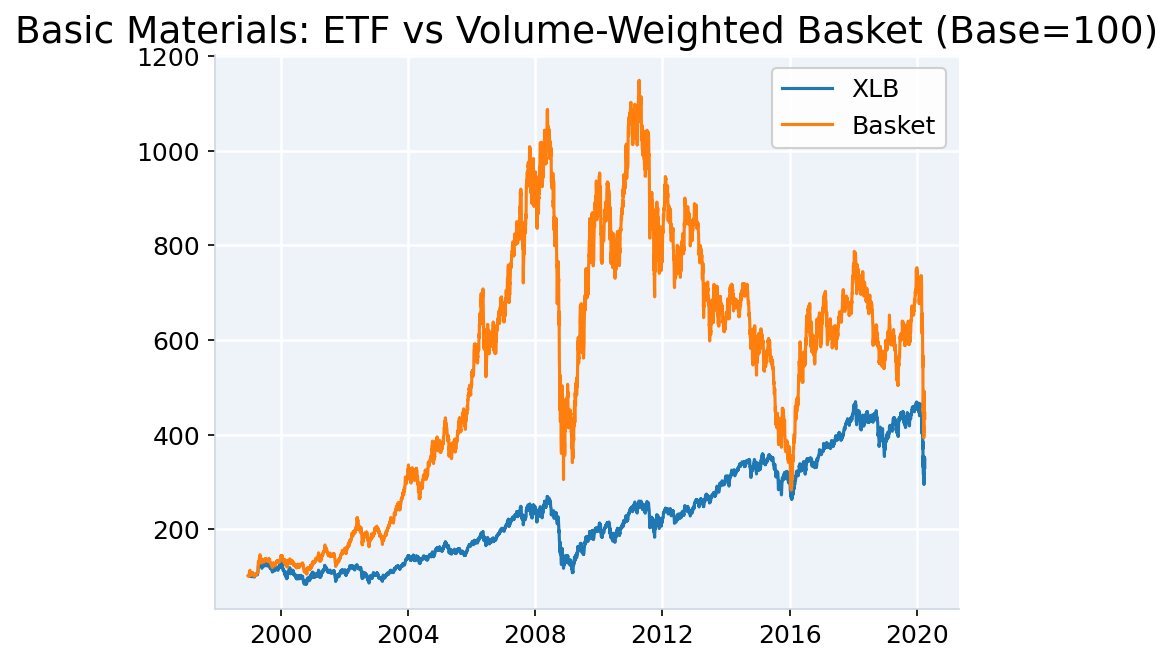

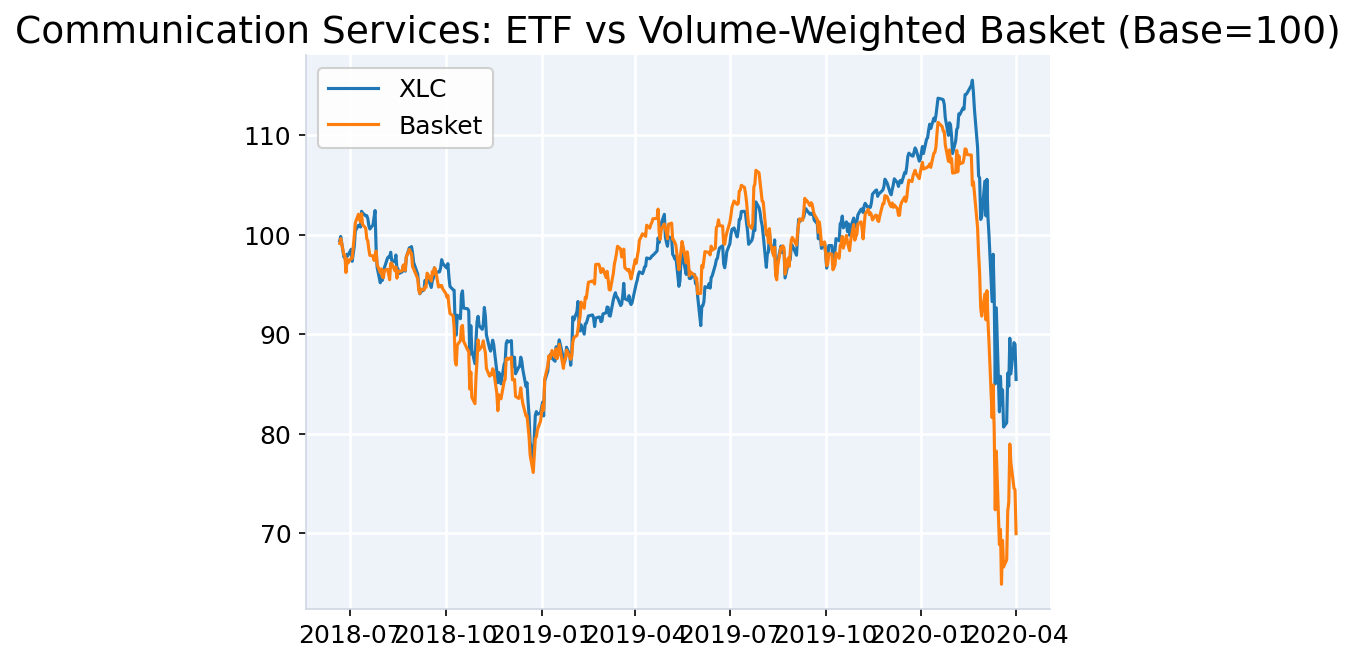

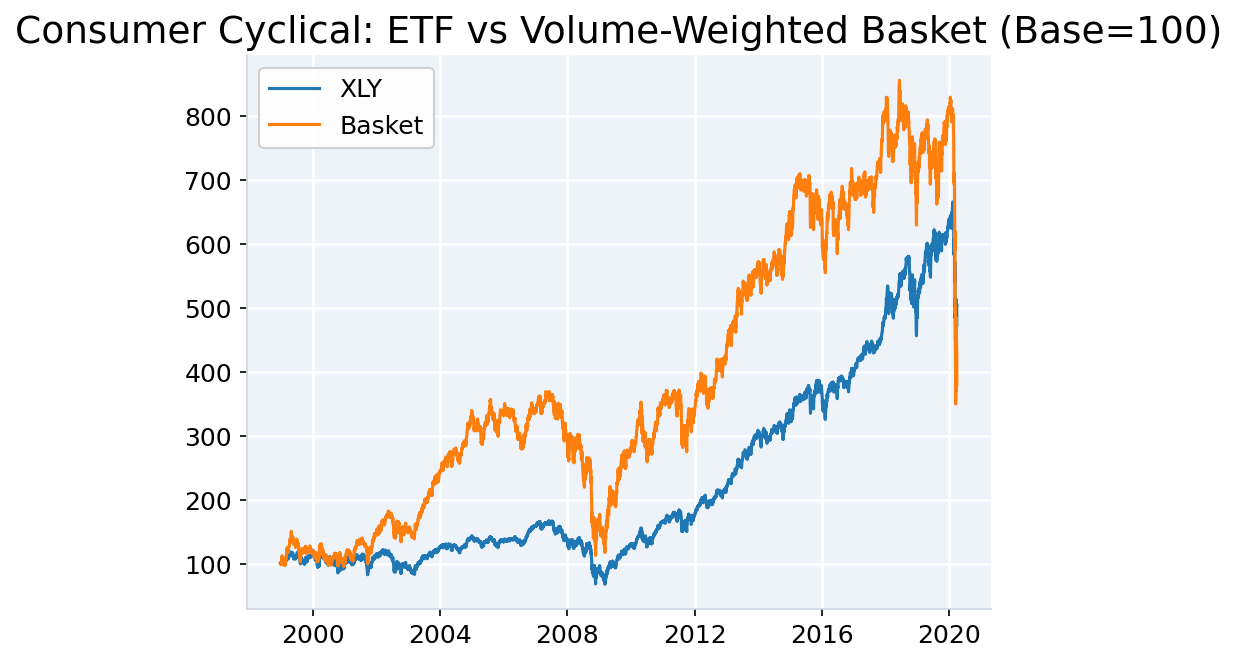

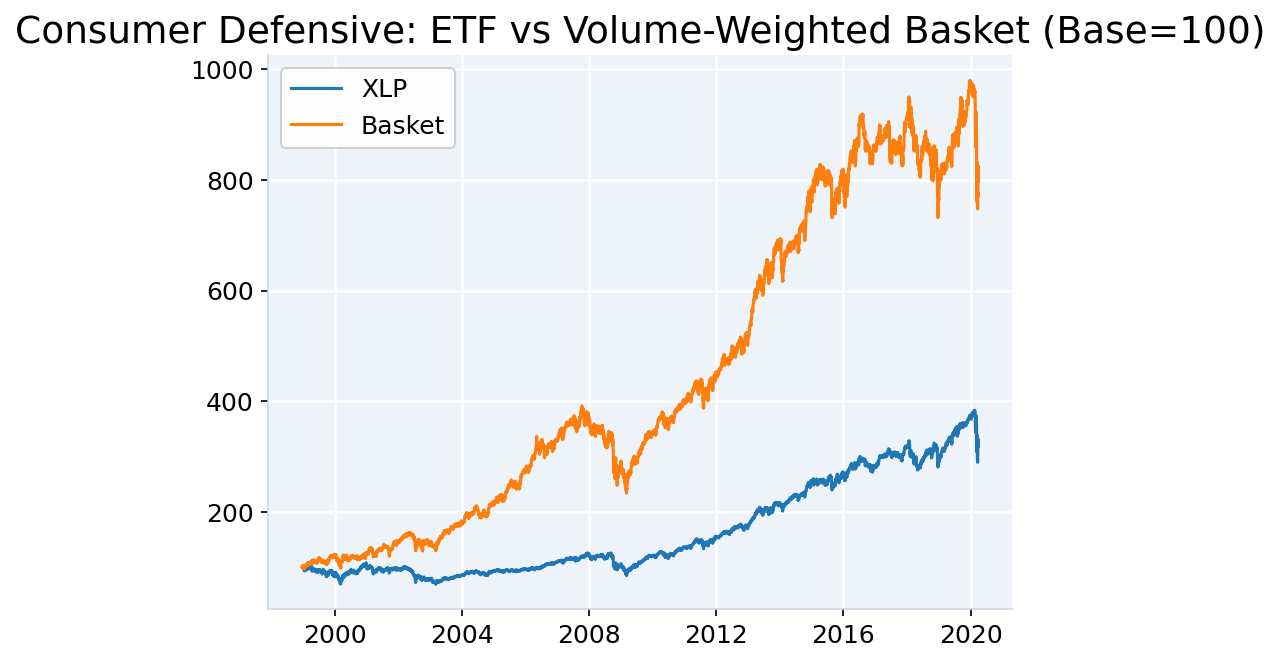

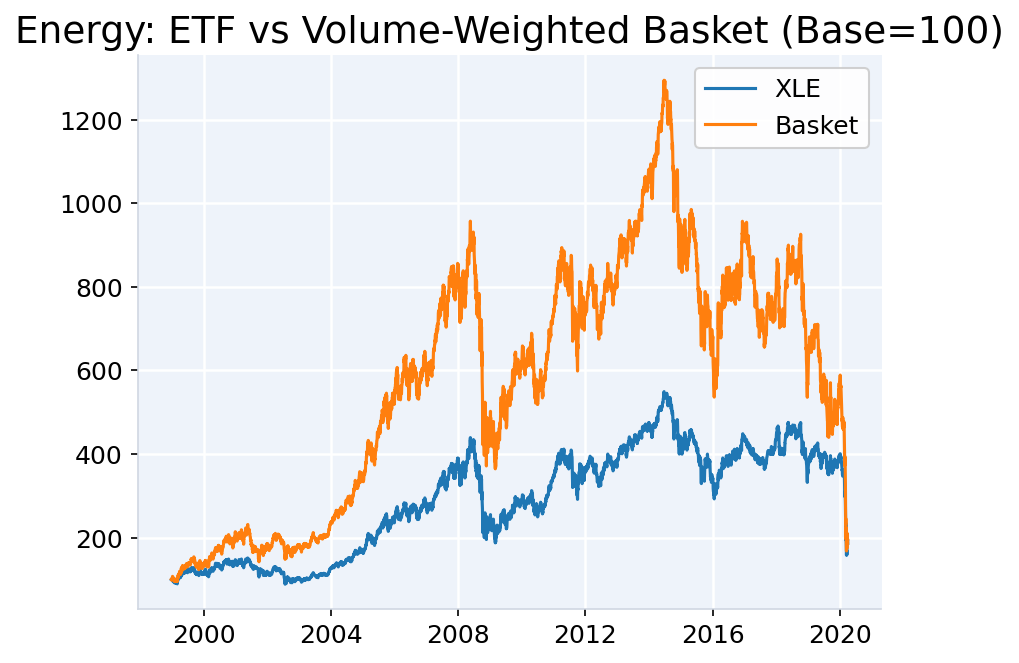

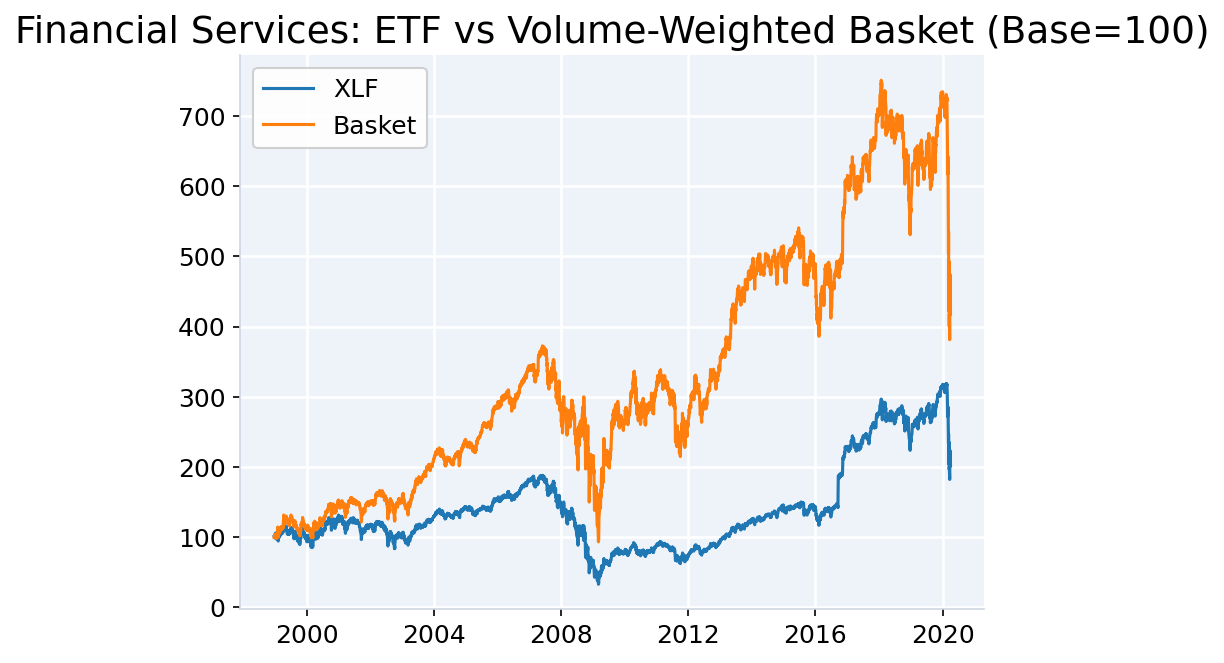

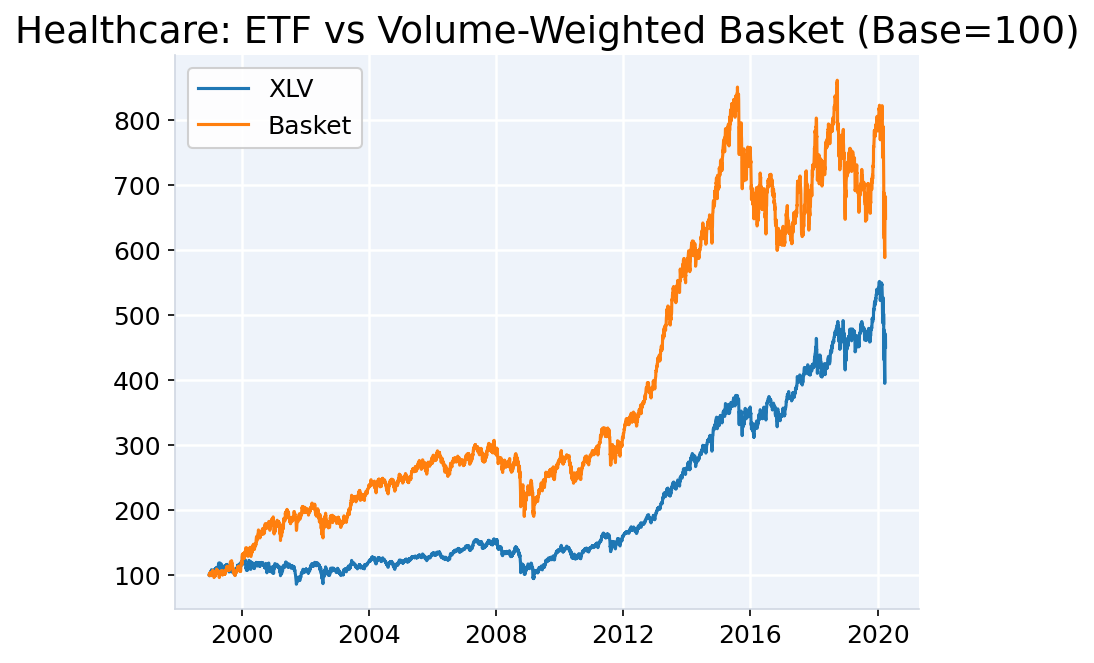

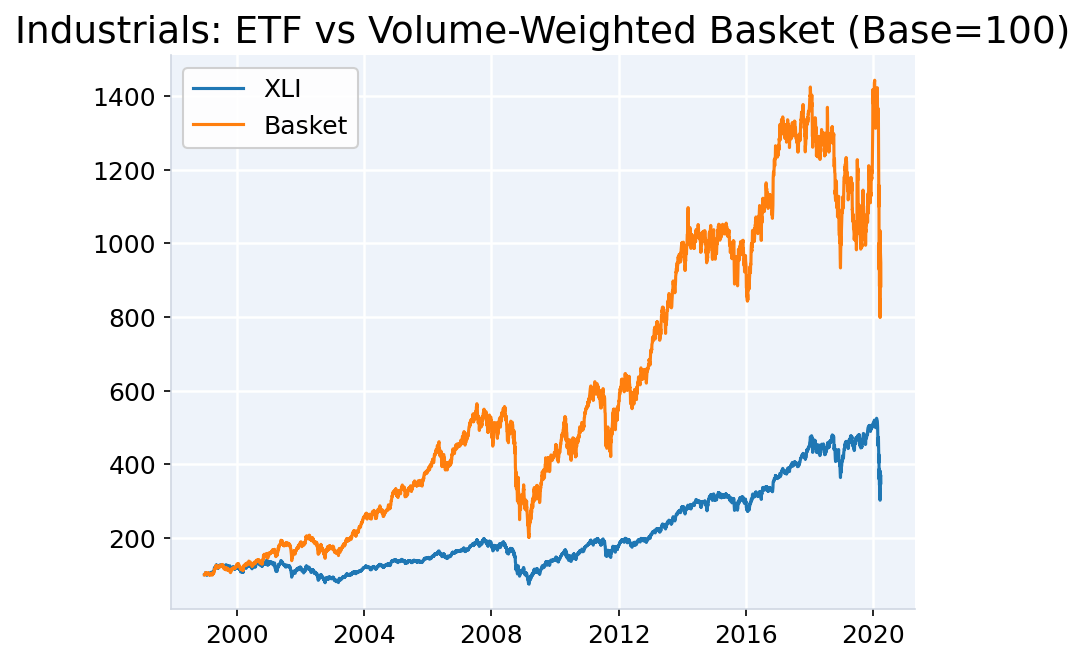

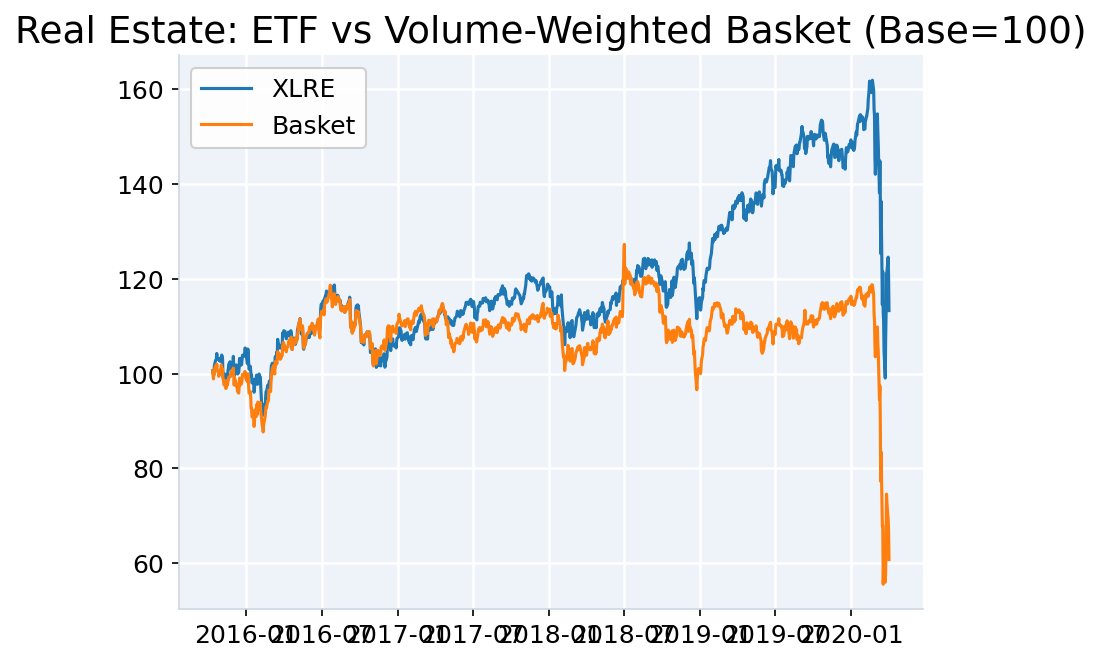

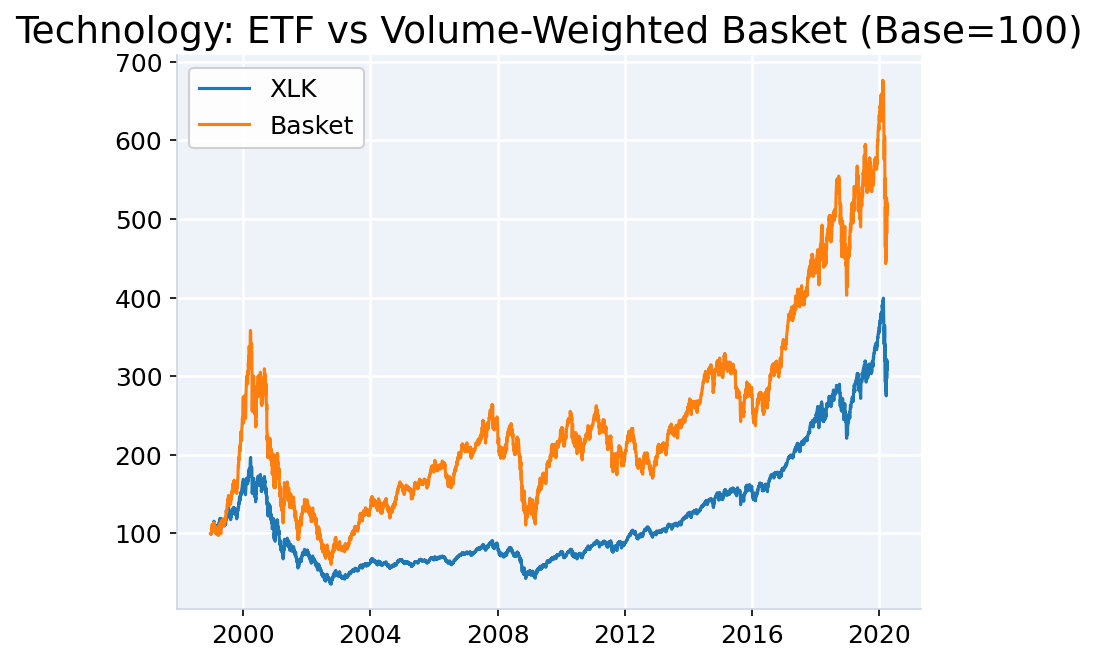

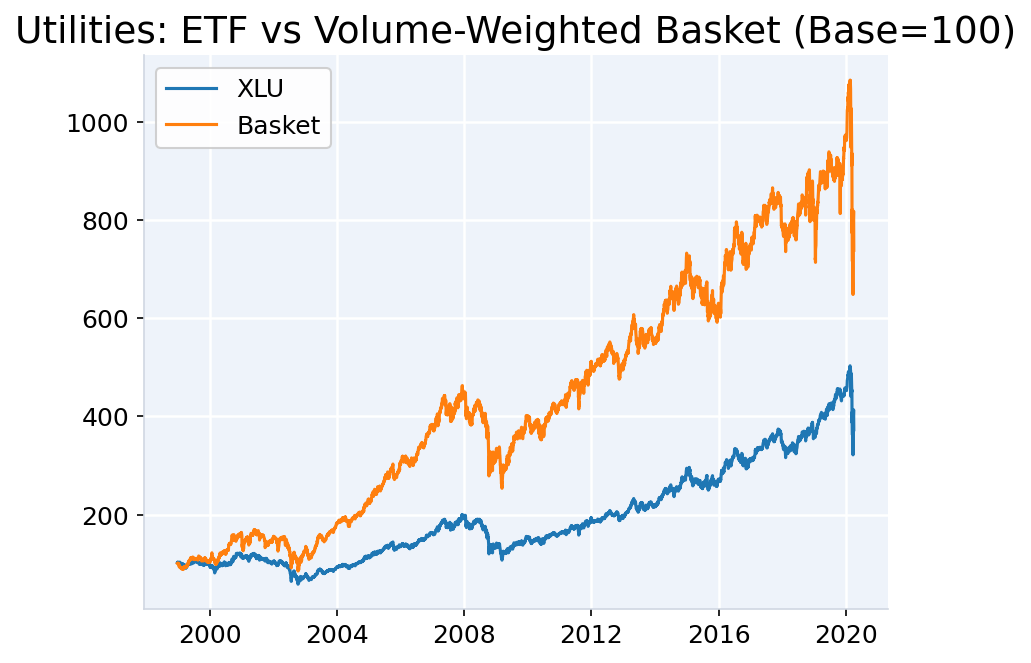

In [10]:
for sector_name in sector_etfs.keys():
    if sector_name in series:
        plot_sector(sector_name)
    else:
        print(f"Skipping {sector_name} (no data in series)")


In [11]:
def plot_volatility_pretty(sector_name, df, win=60, etf_label=None):
    df = df.dropna().copy()
    etf = df["ETF"]
    bsk = df["Basket"]

    vol_etf = etf.rolling(win).std() * np.sqrt(252)
    vol_bsk = bsk.rolling(win).std() * np.sqrt(252)

    if etf_label is None:
        etf_label = sector_etfs.get(sector_name, "ETF")

    fig, ax = plt.subplots(figsize=(13, 5.2))

    ax.plot(vol_bsk.index, vol_bsk.values, linewidth=2.6, label=f"{sector_name} proxy vol")
    ax.plot(vol_etf.index, vol_etf.values, linewidth=2.6, label=f"{etf_label} vol")

    ax.set_title(f"{sector_name}: Rolling Volatility Comparison ({win}d, annualized)", pad=16)
    ax.set_ylabel("Annualized volatility")
    ax.set_xlabel("")

    ax.xaxis.set_major_locator(mdates.YearLocator(base=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.YearLocator())

    ax.tick_params(axis="both", which="both", length=0)
    ax.legend(loc="upper left")

    plt.tight_layout()
    return fig, ax


In [49]:
OUTROOT = "chapter3_sector_png_split_pretty"
vol_dir = os.path.join(OUTROOT, "volatility")
os.makedirs(vol_dir, exist_ok=True)

def safe_name(s):
    return s.replace("&", "and").replace("/", "-").replace(" ", "_").lower()

WIN = 60  # change to 120 if you want

for sector_name, df in series.items():
    if df.dropna().empty:
        continue

    fig, ax = plot_volatility_pretty(sector_name, df, win=WIN, etf_label=sector_etfs.get(sector_name))
    path = os.path.join(vol_dir, safe_name(sector_name) + f"_vol{WIN}.png")
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)

print("Saved pretty volatility plots to:", vol_dir)


Saved pretty volatility plots to: chapter3_sector_png_split_pretty\volatility


In [12]:
def plot_performance_pretty(sector_name, df, etf_label=None, title_suffix="(Index=100)"):
    df = df.dropna().copy()
    idx = 100 * np.exp(df[["ETF","Basket"]].cumsum())

    if etf_label is None:
        etf_label = sector_etfs.get(sector_name, "ETF")

    fig, ax = plt.subplots(figsize=(13, 5.2))
    ax.plot(idx.index, idx["Basket"], linewidth=2.6, label=f"{sector_name} proxy")
    ax.plot(idx.index, idx["ETF"],    linewidth=2.6, label=f"{etf_label} (ETF)")

    ax.set_title(f"{sector_name}: Representative vs Sector Proxy {title_suffix}", pad=16)
    ax.set_ylabel("Index (base = 100)")
    ax.set_xlabel("")

    # nicer date ticks
    ax.xaxis.set_major_locator(mdates.YearLocator(base=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.YearLocator())

    # soften y formatting
    ax.tick_params(axis="both", which="both", length=0)
    ax.legend(loc="upper left")

    plt.tight_layout()
    return fig, ax

In [52]:
OUTROOT = "chapter3_sector_png_split_pretty"
perf_dir = os.path.join(OUTROOT, "performance")
os.makedirs(perf_dir, exist_ok=True)

def safe_name(s):
    return s.replace("&", "and").replace("/", "-").replace(" ", "_").lower()

for sector_name, df in series.items():
    if df.dropna().empty:
        continue

    fig, ax = plot_performance_pretty(sector_name, df, etf_label=sector_etfs.get(sector_name))
    path = os.path.join(perf_dir, safe_name(sector_name) + ".png")
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)

print("Saved pretty performance plots to:", perf_dir)


Saved pretty performance plots to: chapter3_sector_png_split_pretty\performance


## Performance + Volatility (Demo) — ETF vs DIY Sector Basket

### Intro (what this section is doing)
This section compares a **sector ETF** (e.g., XLK) with a **DIY sector proxy (“basket”)** built from the sector’s underlying stocks using a **volume-weighted** construction. The goal is to check whether the ETF delivers exposure that is **similar** to what you would get from a transparent, rules-based basket—and to see how their **risk** evolves through time.

---

## Plot 1 — Performance (Index = 100)

**What the plot shows**  
Both series are rebased to **100 on the same start date**, so the chart is comparing **growth paths**, not absolute prices.

- **ETF**: the sector ETF.
- **Basket**: a DIY proxy built from the sector’s stocks using **volume-weighted** weights .

**How to interpret it**
- If the two lines **track closely**, the ETF and the basket provide **similar exposure** (at least in aggregate).
- If the lines **drift apart**, the ETF and the basket are capturing **different exposure**, typically due to:
  - differences in **constituents** (inclusions/exclusions),
  - differences in **weighting rules** (cap-weighted vs your volume-weighted method),
  - caps/constraints that change concentration.

---

## Plot 2 — Volatility (Rolling, Annualized)

**What the plot shows**  
Rolling annualized **volatility** summarizes “how wild the ride is” (risk) and how that risk changes over time.

It answers:
- **When was the sector risky?**
- **Did ETF and basket risk spike at the same times?**
- **Is one consistently smoother or more explosive during stress?**

**How to interpret it**
- Volatility and performance are related but not the same:
  - **Similar performance, different volatility**: one path is smoother, the other bumpier.
  - **Similar volatility, different performance**: they take different bets and drift apart.
  - **Different regimes**: one may react more strongly in crises even if long-run growth is similar.

---

## Method note (short)
- We compute **daily log returns**.
- ETF and basket are **aligned on identical trading dates**.


---

## Small conclusion (what this section should conclude)
Overall, the **DIY stock basket** tends to **outperform the sector ETF** in this demo. The main exception is the **housing market**, where the **ETF performs better** than the basket. In terms of risk, the **ETFs are generally less volatile** than the stock baskets, meaning the ETF path is typically smoother even when long-run performance is similar or lower. This points to a trade-off: the basket often delivers higher returns, but the ETF usually provides a less bumpy ride.

